In [1]:
import nltk
import random

from nltk.corpus import names

nltk.download('names')

def gender_features(word):
    return {'last_letter': word[-1].lower()}

print(gender_features('Obama'))

{'last_letter': 'a'}


[nltk_data] Downloading package names to /root/nltk_data...
[nltk_data]   Unzipping corpora/names.zip.


In [2]:
male_names = names.words('male.txt')
female_names = names.words('female.txt')

all_names = names.words()

print("Total names:", len(all_names))
print("Male names:", len(male_names))
print("Female names:", len(female_names))

Total names: 7944
Male names: 2943
Female names: 5001


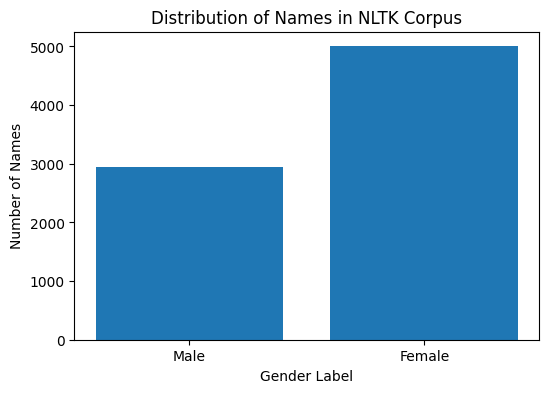

In [13]:
import matplotlib.pyplot as plt

labels = ['Male', 'Female']
counts = [len(male_names), len(female_names)]

plt.figure(figsize=(6, 4))
plt.bar(labels, counts)
plt.title('Distribution of Names in NLTK Corpus')
plt.xlabel('Gender Label')
plt.ylabel('Number of Names')
plt.show()

In [3]:
male_labeled = [(name, 'male') for name in male_names]

female_labeled = [(name, 'female') for name in female_names]

labeled_names = male_labeled + female_labeled

random.shuffle(labeled_names)

print(labeled_names[:10])

[('Carline', 'female'), ('Edwin', 'male'), ('Kimberlee', 'female'), ('Cammy', 'male'), ('Constancia', 'female'), ('Raine', 'female'), ('Cherlyn', 'female'), ('Flemming', 'male'), ('Patience', 'female'), ('Edythe', 'female')]


In [4]:
featuresets = [
    (gender_features(name), gender)
    for name, gender in labeled_names
]

train_set = featuresets[5000:]
test_set = featuresets[:2000]

print("Training samples:", len(train_set))
print("Testing samples:", len(test_set))

Training samples: 2944
Testing samples: 2000


In [5]:
classifier = nltk.NaiveBayesClassifier.train(train_set)

print(classifier.classify(gender_features('David')))

print(classifier.classify(gender_features('Obama')))

accuracy = nltk.classify.accuracy(classifier, test_set)

print("Accuracy:", accuracy)

classifier.show_most_informative_features(10)

male
female
Accuracy: 0.775
Most Informative Features
             last_letter = 'k'              male : female =     33.0 : 1.0
             last_letter = 'a'            female : male   =     28.3 : 1.0
             last_letter = 'o'              male : female =      9.5 : 1.0
             last_letter = 'd'              male : female =      9.0 : 1.0
             last_letter = 'm'              male : female =      7.5 : 1.0
             last_letter = 'f'              male : female =      7.3 : 1.0
             last_letter = 'p'              male : female =      7.3 : 1.0
             last_letter = 'r'              male : female =      5.7 : 1.0
             last_letter = 'g'              male : female =      5.3 : 1.0
             last_letter = 'v'              male : female =      5.0 : 1.0


In [6]:
from sklearn.feature_extraction.text import CountVectorizer

corpus = [
    "Tesseract is good optical character recognition engine",
    "Optical character recognition is significant"
]

print("Corpus:")
for document in corpus:
    print(document)

Corpus:
Tesseract is good optical character recognition engine
Optical character recognition is significant


In [7]:
vect = CountVectorizer(binary=True)

vect.fit(corpus)

vocab = vect.vocabulary_

print("Vocabulary:")
for word in sorted(vocab.keys()):
    print("{} : {}".format(word, vocab[word]))

Vocabulary:
character : 0
engine : 1
good : 2
is : 3
optical : 4
recognition : 5
significant : 6
tesseract : 7


In [8]:
new_document = ["This is a good optical illusion"]

vector = vect.transform(new_document)

print(vector.toarray())

[[0 0 1 1 1 0 0 0]]


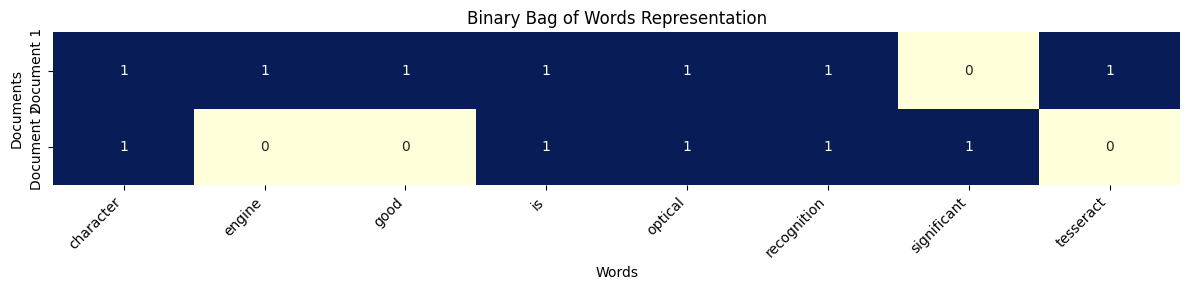

In [14]:
import pandas as pd
import seaborn as sns

bow_matrix = vect.transform(corpus).toarray()

bow_df = pd.DataFrame(
    bow_matrix,
    columns=vect.get_feature_names_out(),
    index=['Document 1', 'Document 2']
)

plt.figure(figsize=(12, 3))
sns.heatmap(bow_df, annot=True, cmap='YlGnBu', cbar=False, fmt='d')
plt.title('Binary Bag of Words Representation')
plt.xlabel('Words')
plt.ylabel('Documents')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [9]:
vect_default = CountVectorizer()

vect_binary = CountVectorizer(binary=True)

vect_stopwords = CountVectorizer(stop_words='english')

vect_ngram = CountVectorizer(ngram_range=(1, 2))

for name, vectorizer in [
    ("Default", vect_default),
    ("Binary", vect_binary),
    ("Stopwords removed", vect_stopwords),
    ("Unigrams and bigrams", vect_ngram)
]:

    vectorizer.fit(corpus)

    print("\n", name)
    print(vectorizer.vocabulary_)


 Default
{'tesseract': 7, 'is': 3, 'good': 2, 'optical': 4, 'character': 0, 'recognition': 5, 'engine': 1, 'significant': 6}

 Binary
{'tesseract': 7, 'is': 3, 'good': 2, 'optical': 4, 'character': 0, 'recognition': 5, 'engine': 1, 'significant': 6}

 Stopwords removed
{'tesseract': 6, 'good': 2, 'optical': 3, 'character': 0, 'recognition': 4, 'engine': 1, 'significant': 5}

 Unigrams and bigrams
{'tesseract': 14, 'is': 5, 'good': 3, 'optical': 8, 'character': 0, 'recognition': 10, 'engine': 2, 'tesseract is': 15, 'is good': 6, 'good optical': 4, 'optical character': 9, 'character recognition': 1, 'recognition engine': 11, 'significant': 13, 'recognition is': 12, 'is significant': 7}


In [10]:
from sklearn.metrics.pairwise import cosine_similarity

doc1 = ["Google Cloud Vision is a character recognition engine"]

doc2 = ["OCR is an optical character recognition engine"]

In [11]:
vector1 = vect.transform(doc1)
vector2 = vect.transform(doc2)

similarity = cosine_similarity(
    vector1.toarray(),
    vector2.toarray()
)

print("Cosine Similarity:")
print(similarity)

Cosine Similarity:
[[0.89442719]]


In [12]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

documents = [
    "Google Cloud Vision is a character recognition engine",
    "OCR is an optical character recognition engine"
]

vectorizer = CountVectorizer(binary=True)

document_vectors = vectorizer.fit_transform(documents)

print("Vocabulary:")
print(vectorizer.vocabulary_)

print("\nDocument vectors:")
print(document_vectors.toarray())

similarity = cosine_similarity(document_vectors)

print("\nCosine Similarity Matrix:")
print(similarity)

Vocabulary:
{'google': 4, 'cloud': 2, 'vision': 9, 'is': 5, 'character': 1, 'recognition': 8, 'engine': 3, 'ocr': 6, 'an': 0, 'optical': 7}

Document vectors:
[[0 1 1 1 1 1 0 0 1 1]
 [1 1 0 1 0 1 1 1 1 0]]

Cosine Similarity Matrix:
[[1.         0.57142857]
 [0.57142857 1.        ]]


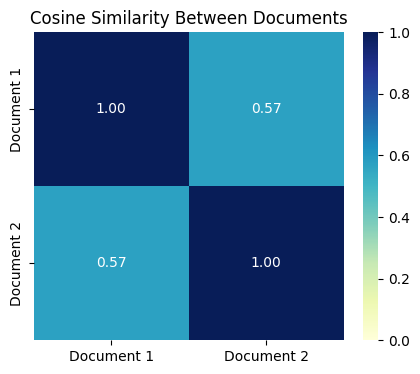

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# Use the vectors from Cell 12
similarity_matrix = cosine_similarity(document_vectors)

plt.figure(figsize=(5, 4))
sns.heatmap(
    similarity_matrix,
    annot=True,
    cmap='YlGnBu',
    vmin=0,
    vmax=1,
    xticklabels=['Document 1', 'Document 2'],
    yticklabels=['Document 1', 'Document 2'],
    fmt='.2f'
)
plt.title('Cosine Similarity Between Documents')
plt.show()